# Đồ thị 11 Cột chồng theo nhóm tuổi và nhãn kết quả

**Võ Minh Huy — 2311110117**

Tổng hợp đủ 299 hồ sơ theo MaNhomTuoi và DEATH_EVENT. Nhóm tuổi: A1 dưới 50; A2 từ 50 đến dưới 60; A3 từ 60 đến dưới 70; A4 từ 70 trở lên. Giữ riêng nhãn chờ xác minh, không tự gán về 0 hoặc 1.

Đây là biểu đồ số lượng, không phải cột chồng 100%. Chiều cao toàn cột là tổng số hồ sơ nhóm tuổi; từng đoạn là số hồ sơ thuộc một nhóm nhãn. Cỡ các nhóm tuổi khác nhau nên không dùng chiều cao đoạn để suy ra nguy cơ tử vong.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
for cot in ["age","MaNhomTuoi","DEATH_EVENT"]:
    du_lieu[cot] = pd.to_numeric(du_lieu[cot],errors="raise")
assert len(du_lieu) == 299
assert du_lieu["age"].between(40,95).all()
assert du_lieu["MaNhomTuoi"].isin([1,2,3,4]).all()
ma_tu_tuoi = np.select([du_lieu["age"]<50,du_lieu["age"]<60,du_lieu["age"]<70],[1,2,3],default=4)
assert np.array_equal(ma_tu_tuoi,du_lieu["MaNhomTuoi"].to_numpy())
nhan = du_lieu["DEATH_EVENT"]
if (nhan.notna() & ~nhan.isin([0,1])).any():
    raise ValueError("Có nhãn ngoài miền 0/1.")
nhan_nhom = nhan.map({0:"Nhan0",1:"Nhan1"}).fillna("ChoXacMinh")
bang = pd.crosstab(du_lieu["MaNhomTuoi"],nhan_nhom).reindex(index=[1,2,3,4],columns=["Nhan0","Nhan1","ChoXacMinh"],fill_value=0)
bang.index = bang.index.astype(int)
bang.index.name = "MaNhomTuoi"
bang["SoHoSo"] = bang.sum(axis=1)
assert bang["SoHoSo"].tolist() == [42,77,111,69]
assert bang[["Nhan0","Nhan1","ChoXacMinh"]].sum().tolist() == [203,95,1]
assert bang["SoHoSo"].sum() == 299
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/11_cot_chong_tuoi_nhan"
thu_muc_kq.mkdir(parents=True,exist_ok=True)
bang_tong_hop = bang.reset_index()
bang_tong_hop.insert(1,"KhoangTuoi",["Dưới 50","50 đến dưới 60","60 đến dưới 70","Từ 70 trở lên"])
bang_tong_hop


DEATH_EVENT,MaNhomTuoi,KhoangTuoi,Nhan0,Nhan1,ChoXacMinh,SoHoSo
0,1,Dưới 50,34,8,0,42
1,2,50 đến dưới 60,59,18,0,77
2,3,60 đến dưới 70,73,37,1,111
3,4,Từ 70 trở lên,37,32,0,69


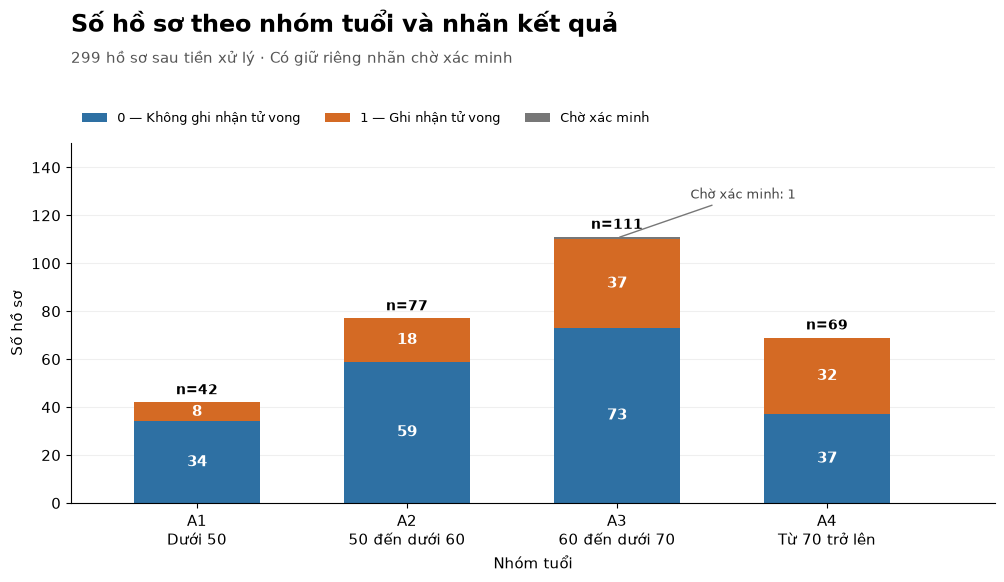

In [2]:
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11})
fig, ax = plt.subplots(figsize=(10.5,6.2))
fig.subplots_adjust(top=0.76,bottom=0.18,left=0.10,right=0.98)
fig.text(0.10,0.94,"Số hồ sơ theo nhóm tuổi và nhãn kết quả",fontsize=17,weight="bold")
fig.text(0.10,0.89,"299 hồ sơ sau tiền xử lý · Có giữ riêng nhãn chờ xác minh",color="#555555")
x = np.arange(4)
day = np.zeros(4)
for cot, mau, ten in [("Nhan0","#2E70A3","0 — Không ghi nhận tử vong"),
    ("Nhan1","#D46A24","1 — Ghi nhận tử vong"),("ChoXacMinh","#777777","Chờ xác minh")]:
    so = bang[cot].to_numpy()
    ax.bar(x,so,bottom=day,color=mau,width=0.60,label=ten)
    for i, n in enumerate(so):
        if n >= 4:
            ax.text(i,day[i]+n/2,str(n),ha="center",va="center",color="white",weight="bold")
        elif n > 0:
            ax.annotate(f"Chờ xác minh: {n}",xy=(i,day[i]+n/2),xytext=(i+0.35,day[i]+n+16),
                ha="left",fontsize=9,color="#444444",arrowprops={"arrowstyle":"-","color":"#777777"})
    day += so
assert np.array_equal(day,bang["SoHoSo"].to_numpy())
for i, n in enumerate(day):
    ax.text(i,n+2,f"n={int(n)}",ha="center",va="bottom",fontsize=10,weight="bold")
ax.set_xticks(x,labels=["A1\nDưới 50","A2\n50 đến dưới 60","A3\n60 đến dưới 70","A4\nTừ 70 trở lên"])
ax.set(xlabel="Nhóm tuổi",ylabel="Số hồ sơ",ylim=(0,150),xlim=(-0.6,3.8))
ax.grid(axis="y",alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.legend(frameon=False,loc="lower left",bbox_to_anchor=(0,1.02),ncol=3,fontsize=9)
fig.savefig(thu_muc_kq / "11_cot_chong_tuoi_nhan.png",dpi=300,bbox_inches="tight",facecolor="white")
bang_tong_hop.to_csv(thu_muc_kq / "tong_hop_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

Bốn nhóm tuổi có 42, 77, 111 và 69 hồ sơ; A3 có tổng số hồ sơ cao nhất. Tổng các đoạn nhãn là 203 nhãn 0, 95 nhãn 1 và 1 chờ xác minh, bao phủ đủ 299 hồ sơ. Dùng bảng tổng hợp để đọc số lượng từng đoạn.

Cột thể hiện số lượng, không thể hiện tỷ lệ tử vong đã điều chỉnh theo quy mô nhóm hoặc thời gian theo dõi. Không suy ra quan hệ nhân quả hay xu hướng theo thời gian từ bốn nhóm tuổi. Nhóm tuổi được tính từ tuổi sau N02, có cả tuổi đã điền; nhãn chờ xác minh vẫn giữ thiếu trong file after.
